In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)
from lightgbm import LGBMClassifier

from src.config import (
    PROCESSED_DATA_PATH,
    FIGURES_DIR,
    PR_ROC_CURVE_PATH,
    RANDOM_STATE,
    TEST_SIZE,
    CV_FOLDS,
)



sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED_DATA_PATH)

# Відділяємо ідентифікатор та цільову змінну
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

# Стратифіковане розбиття зберігає пропорцію класів (26.5% Churn) в обох частинах
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Train розмір: {X_train.shape}, частка Churn: {y_train.mean():.3f}")
print(f"Test розмір:  {X_test.shape}, частка Churn: {y_test.mean():.3f}")

Train розмір: (5634, 24), частка Churn: 0.265
Test розмір:  (1409, 24), частка Churn: 0.265


In [2]:
num_features = [
    "SeniorCitizen",
    "tenure",
    "active_addons_count",
    "MonthlyCharges",
    "TotalCharges",
    "charge_to_contract_avg_ratio",
    "diff_from_internet_avg",
    "charge_pct_rank_in_contract",
]

cat_features = [col for col in X_train.columns if col not in num_features]

print(f"Числових ознак: {len(num_features)}")
print(f"Категоріальних ознак: {len(cat_features)}")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features),
    ],
    remainder="drop",
)

Числових ознак: 8
Категоріальних ознак: 16


In [3]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, C=1.0, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=30,
        subsample_for_bin=5000,
        random_state=RANDOM_STATE,
        verbose=-1,
    ),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_results = []
trained_pipelines = {}

for name, estimator in models.items():
    pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", estimator),
        ]
    )

    scores = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )

    cv_results.append(
        {
            "Model": name,
            "ROC-AUC (mean)": round(scores["test_roc_auc"].mean(), 4),
            "ROC-AUC (std)": round(scores["test_roc_auc"].std(), 4),
            "PR-AUC (mean)": round(scores["test_pr_auc"].mean(), 4),
            "PR-AUC (std)": round(scores["test_pr_auc"].std(), 4),
        }
    )

    # Навчаємо пайплайн на всьому X_train для подальшої перевірки на X_test
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

results_df = pd.DataFrame(cv_results).sort_values("PR-AUC (mean)", ascending=False)
display(results_df)

,Model,ROC-AUC (mean),ROC-AUC (std),PR-AUC (mean),PR-AUC (std)
1,Random Forest,0.8427,0.0100,0.6581,0.0169
2,LightGBM,0.8405,0.0078,0.6560,0.0176
0,Logistic Regression,0.8431,0.0110,0.6544,0.0143


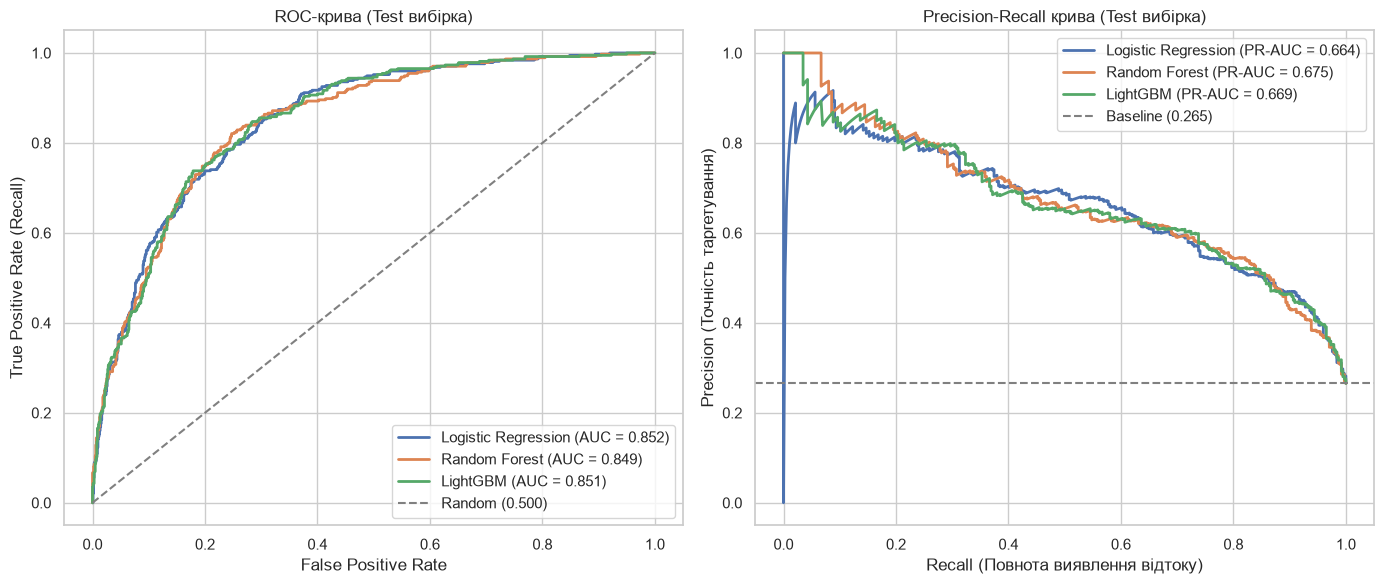

Графік збережено: C:\D\Progamirovanie\MLF\Telco-Churn-Prediction\customer-churn-prediction\reports\figures\roc_pr_curves.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, pipe in trained_pipelines.items():
    y_proba = pipe.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_proba)
    pr_auc = average_precision_score(y_test, y_proba)

    # ROC-крива
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.3f})")

    # Precision-Recall крива
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    axes[1].plot(recall, precision, lw=2, label=f"{name} (PR-AUC = {pr_auc:.3f})")

# Оформлення ROC
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (0.500)")
axes[0].set_title("ROC-крива (Test вибірка)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# Оформлення PR
baseline_pr = y_test.mean()
axes[1].axhline(
    baseline_pr, linestyle="--", color="gray", label=f"Baseline ({baseline_pr:.3f})"
)
axes[1].set_title("Precision-Recall крива (Test вибірка)")
axes[1].set_xlabel("Recall (Повнота виявлення відтоку)")
axes[1].set_ylabel("Precision (Точність таргетування)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig(PR_ROC_CURVE_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"Графік збережено: {PR_ROC_CURVE_PATH}")

In [ ]:
import importlib
import src.config
importlib.reload(src.config)

import shap
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from src.config import (
    COST_RETENTION,
    COST_CHURN,
    THRESHOLD_PLOT_PATH,
    SHAP_SUMMARY_PATH,
)



# Автоматично обираємо модель-переможця з найвищим PR-AUC на крос-валідації
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
print(f"Обрана модель для оптимізації порогу та SHAP: {best_model_name}")

# Отримуємо чесні out-of-fold ймовірності на Train для підбору порогу
oof_proba = cross_val_predict(
    best_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]


def calculate_total_cost(y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    total_cost = (tp + fp) * COST_RETENTION + fn * COST_CHURN
    return total_cost, tn, fp, fn, tp


thresholds = np.linspace(0.05, 0.95, 181)
oof_costs = [calculate_total_cost(y_train, oof_proba, t)[0] for t in thresholds]

best_idx = int(np.argmin(oof_costs))
optimal_threshold = float(thresholds[best_idx])
min_oof_cost = oof_costs[best_idx]

print(f"Оптимальний бізнес-поріг (t*): {optimal_threshold:.3f}")
print(f"Мінімальні витрати на Train (OOF): ${min_oof_cost:,.0f}")

Обрана модель для оптимізації порогу та SHAP: Random Forest
Оптимальний бізнес-поріг (t*): 0.205
Мінімальні витрати на Train (OOF): $74,980


,Стратегія,Поріг,Залучено в кампанію (TP+FP),Пропущено відтоків (FN),Сукупні витрати ($)
0,1. Без моделі (ніхто не отримує знижку),1.000,0,374,37400
1,2. Стандартний ML-поріг,0.500,287,186,24340
2,3. Оптимізований бізнес-поріг (t*),0.205,728,40,18560


Економія від оптимізації порогу на Test (1 409 клієнтів): $5,780 (-23.7% витрат)


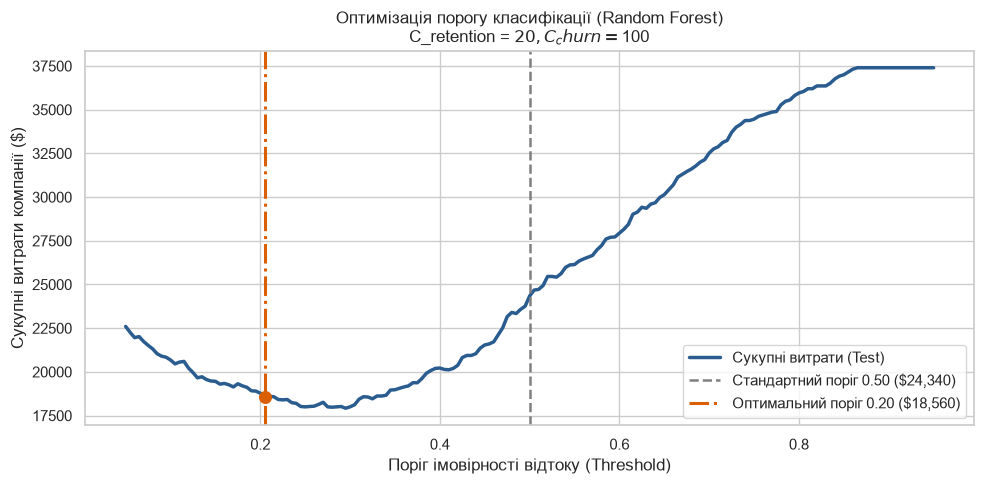

Графік збережено: C:\D\Progamirovanie\MLF\Telco-Churn-Prediction\customer-churn-prediction\reports\figures\threshold_cost.png


In [7]:
test_proba = best_pipeline.predict_proba(X_test)[:, 1]
test_costs = [calculate_total_cost(y_test, test_proba, t)[0] for t in thresholds]

# Порівняння 3 бізнес-стратегій на Test
cost_no_model = y_test.sum() * COST_CHURN
cost_default, _, fp_def, fn_def, tp_def = calculate_total_cost(y_test, test_proba, 0.50)
cost_optimal, _, fp_opt, fn_opt, tp_opt = calculate_total_cost(
    y_test, test_proba, optimal_threshold
)

summary_business = pd.DataFrame(
    [
        {
            "Стратегія": "1. Без моделі (ніхто не отримує знижку)",
            "Поріг": 1.00,
            "Залучено в кампанію (TP+FP)": 0,
            "Пропущено відтоків (FN)": int(y_test.sum()),
            "Сукупні витрати ($)": cost_no_model,
        },
        {
            "Стратегія": "2. Стандартний ML-поріг",
            "Поріг": 0.50,
            "Залучено в кампанію (TP+FP)": tp_def + fp_def,
            "Пропущено відтоків (FN)": fn_def,
            "Сукупні витрати ($)": cost_default,
        },
        {
            "Стратегія": "3. Оптимізований бізнес-поріг (t*)",
            "Поріг": round(optimal_threshold, 3),
            "Залучено в кампанію (TP+FP)": tp_opt + fp_opt,
            "Пропущено відтоків (FN)": fn_opt,
            "Сукупні витрати ($)": cost_optimal,
        },
    ]
)
display(summary_business)

savings_vs_default = cost_default - cost_optimal
print(
    f"Економія від оптимізації порогу на Test (1 409 клієнтів): "
    f"${savings_vs_default:,.0f} (-{savings_vs_default / cost_default * 100:.1f}% витрат)"
)

# Візуалізація кривої витрат
plt.figure(figsize=(10, 5))
plt.plot(thresholds, test_costs, lw=2.5, color="#2b5c8f", label="Сукупні витрати (Test)")
plt.axvline(
    0.50,
    color="gray",
    linestyle="--",
    lw=1.8,
    label=f"Стандартний поріг 0.50 (${cost_default:,.0f})",
)
plt.axvline(
    optimal_threshold,
    color="#d95f02",
    linestyle="-.",
    lw=2.2,
    label=f"Оптимальний поріг {optimal_threshold:.2f} (${cost_optimal:,.0f})",
)
plt.scatter([optimal_threshold], [cost_optimal], color="#d95f02", s=70, zorder=5)

plt.title(
    f"Оптимізація порогу класифікації ({best_model_name})\n"
    f"C_retention = ${COST_RETENTION}, C_churn = ${COST_CHURN}"
)
plt.xlabel("Поріг імовірності відтоку (Threshold)")
plt.ylabel("Сукупні витрати компанії ($)")
plt.legend()
plt.tight_layout()
plt.savefig(THRESHOLD_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"Графік збережено: {THRESHOLD_PLOT_PATH}")

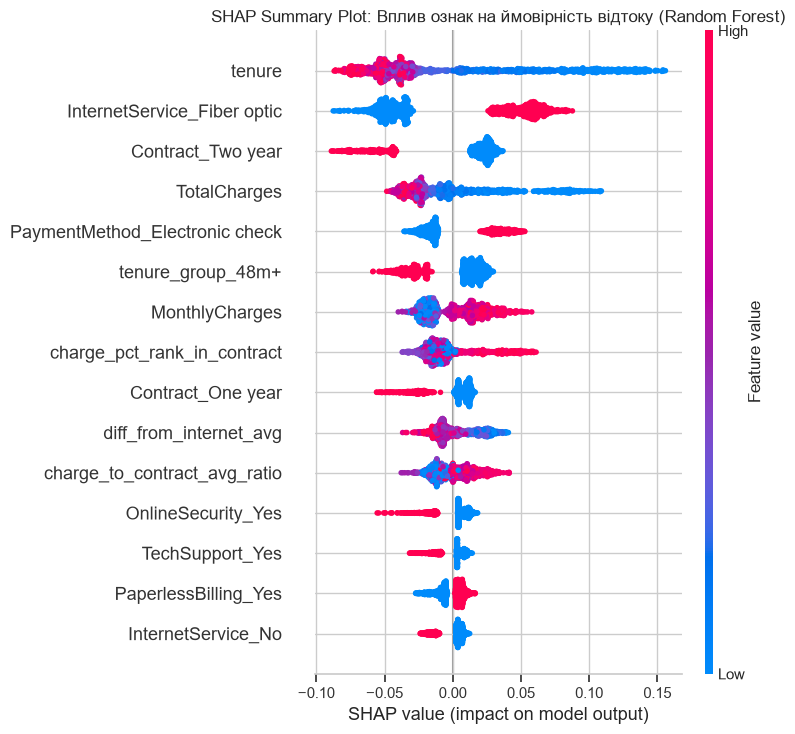

SHAP-графік збережено: C:\D\Progamirovanie\MLF\Telco-Churn-Prediction\customer-churn-prediction\reports\figures\shap_summary.png


In [8]:
preprocessor_fitted = best_pipeline.named_steps["preprocessor"]
classifier_fitted = best_pipeline.named_steps["classifier"]

# Трансформуємо вибірки та отримуємо читабельні назви ознак
X_train_trans = preprocessor_fitted.transform(X_train)
X_test_trans = preprocessor_fitted.transform(X_test)

if hasattr(X_train_trans, "toarray"):
    X_train_trans = X_train_trans.toarray()
    X_test_trans = X_test_trans.toarray()

clean_feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in preprocessor_fitted.get_feature_names_out()
]
X_test_df = pd.DataFrame(X_test_trans, columns=clean_feature_names)

# Розрахунок SHAP-значень для класу 1 (Churn)
if hasattr(classifier_fitted, "coef_"):
    explainer = shap.LinearExplainer(classifier_fitted, X_train_trans)
    shap_vals_churn = explainer.shap_values(X_test_trans)
else:
    explainer = shap.TreeExplainer(classifier_fitted)
    raw_shap = explainer.shap_values(X_test_trans)
    if isinstance(raw_shap, list):
        shap_vals_churn = raw_shap[1]
    elif getattr(raw_shap, "ndim", 2) == 3:
        shap_vals_churn = raw_shap[:, :, 1]
    else:
        shap_vals_churn = raw_shap

# Побудова та збереження SHAP Summary Plot (Top-15 факторів)
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_vals_churn,
    X_test_df,
    max_display=15,
    show=False,
)
plt.title(f"SHAP Summary Plot: Вплив ознак на ймовірність відтоку ({best_model_name})")
plt.tight_layout()
plt.savefig(SHAP_SUMMARY_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"SHAP-графік збережено: {SHAP_SUMMARY_PATH}")